[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture7_notebook.ipynb)

# Blockchain Applications — Lecture 7: Networks, sentiment and asset classes

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

This notebook reproduces the computations of Lecture 7 in the order of the slides:

1. crypto markets as networks: correlation matrix, minimum spanning tree, rolling connectedness and Diebold–Yilmaz spillovers;
2. are cryptos an asset class? A statistical "phenotype" of 33 assets, principal components and $k$-means clusters;
3. an event study of Ether around 13 Ethereum upgrades;
4. sentiment from social media (the BitMood index);
5. appendix (not examined): herding (the CSAD test) and a hedonic price index on simulated digital-art sales.

Data: daily closes from EODHD in the course repository (`data/market`). All samples end on **23 October 2026**, the date used in the lecture.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_7'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

In [2]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['networkx']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

## Setup: packages, chart style and data

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

### Lecture-specific setup

`px(sym)` reads one EODHD file and cuts it at the lecture's end date. For US stocks and funds (symbols ending in `.US`) it uses the
dividend- and split-adjusted close, so that returns include dividends; for coins, indices, FX and gold it uses the close.

In [5]:
from scipy import stats
from scipy.sparse.csgraph import minimum_spanning_tree
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.api import VAR
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import networkx as nx

END = '2026-10-23'                      # last day of the lecture sample


def px(sym):
    """Daily price of one EODHD symbol to END; adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def legend_at_bottom(fig, ncol=3, bottom=0.12):
    """Legend below the plot (shared helper), with room for it at the bottom of the figure."""
    legend_below(fig, ncol)
    fig.tight_layout(rect=(0, bottom, 1, 1))


COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


## 1. Crypto markets as networks

### From correlations to a network

Each coin is a node. The strength of the link between coins $i$ and $j$ is the Pearson correlation $\rho_{ij}$ of their daily log returns,
January 2021 – October 2026. Mantegna (1999) turns the correlation into a metric distance:

$$ d_{ij} = \sqrt{2\,(1 - \rho_{ij})}, \qquad \rho = 1 \Rightarrow d = 0, \quad \rho = 0 \Rightarrow d = \sqrt2 . $$

The **minimum spanning tree (MST)** is the set of $N - 1$ edges that connects all $N$ coins with the smallest total distance:

$$ \mathrm{MST} = \arg\min_{T \text{ spanning tree}} \sum_{(i,j) \in T} d_{ij} . $$

It keeps the strongest links and removes the rest. A **hub** is a coin with many MST edges, that is, a high **degree** (number of edges at the node).
The cell below computes the correlation matrix, the distances and the MST, and prints the worked examples of the slides.

In [6]:
CORR = R.corr()
iu = np.triu_indices(len(COINS), 1)
Dm = np.sqrt(2 * (1 - CORR.values))                       # Mantegna distance
mst = minimum_spanning_tree(np.triu(Dm, 1)).toarray()
G = nx.Graph()
for i, a in enumerate(COINS):
    for j, b in enumerate(COINS):
        if mst[i, j] > 0:
            G.add_edge(a, b, d=mst[i, j], rho=CORR.iloc[i, j])
deg = dict(G.degree())

pairs = CORR.where(np.triu(np.ones(CORR.shape, bool), 1)).stack()
cb = CORR['BTC'].drop('BTC')
print(f'Mean pairwise correlation (171 pairs): {CORR.values[iu].mean():.3f}')
print(f'Lowest pairwise correlation: {pairs.min():.3f} ({pairs.idxmin()[0]}-{pairs.idxmin()[1]})')
print(f'Correlation with BTC: lowest {cb.min():.3f} ({cb.idxmin()}), highest {cb.max():.3f} ({cb.idxmax()})')
for a, b in [('BTC', 'ETH'), ('DOGE', 'TRX')]:
    print(f'Worked example {a}-{b}: correlation {CORR.loc[a, b]:.3f}, distance d = sqrt(2(1 - rho)) = {np.sqrt(2 * (1 - CORR.loc[a, b])):.3f}')
print('\nMST degree (number of MST edges) of each coin:')
print(pd.Series(deg).sort_values(ascending=False).to_string())
edges = pd.DataFrame([(a, b, v['rho'], v['d']) for a, b, v in G.edges(data=True)], columns=['coin 1', 'coin 2', 'correlation', 'distance'])
print('\nThe 18 MST edges:')
print(edges.round(3).to_string(index=False))

Mean pairwise correlation (171 pairs): 0.597
Lowest pairwise correlation: 0.349 (DOGE-TRX)
Correlation with BTC: lowest 0.521 (TRX), highest 0.823 (ETH)
Worked example BTC-ETH: correlation 0.823, distance d = sqrt(2(1 - rho)) = 0.595
Worked example DOGE-TRX: correlation 0.349, distance d = sqrt(2(1 - rho)) = 1.141

MST degree (number of MST edges) of each coin:
DOT     6
ETH     6
ADA     3
ETC     3
BTC     2
LINK    2
XLM     2
LTC     1
XRP     1
SOL     1
BNB     1
XMR     1
AVAX    1
DOGE    1
TRX     1
BCH     1
ATOM    1
FIL     1
ALGO    1

The 18 MST edges:
coin 1 coin 2  correlation  distance
   BTC    ETH        0.823     0.595
   BTC    XMR        0.569     0.929
   ETH    BNB        0.680     0.800
   ETH    SOL        0.677     0.804
   ETH    LTC        0.749     0.708
   ETH   LINK        0.781     0.662
   ETH    ETC        0.759     0.694
  LINK    DOT        0.762     0.690
   ETC   DOGE        0.545     0.954
   ETC    BCH        0.740     0.721
   XRP    XLM       

### What a correlation of 0.82 looks like

Before building the tree, two pairs show what a correlation means on the scatter of daily returns: BTC with ETH, the highest
correlation with Bitcoin, and BTC with Tron (TRX), the lowest. The cell prints the correlation, the least-squares slope of the second coin
on Bitcoin, the share of days on which both move in the same direction, $\rho^2$ and the Mantegna distance.

BTC-ETH: correlation 0.82, slope 1.11, same direction on 82% of days, rho^2 = 0.68, distance d = 0.60
BTC-TRX: correlation 0.52, slope 0.67, same direction on 69% of days, rho^2 = 0.27, distance d = 0.98


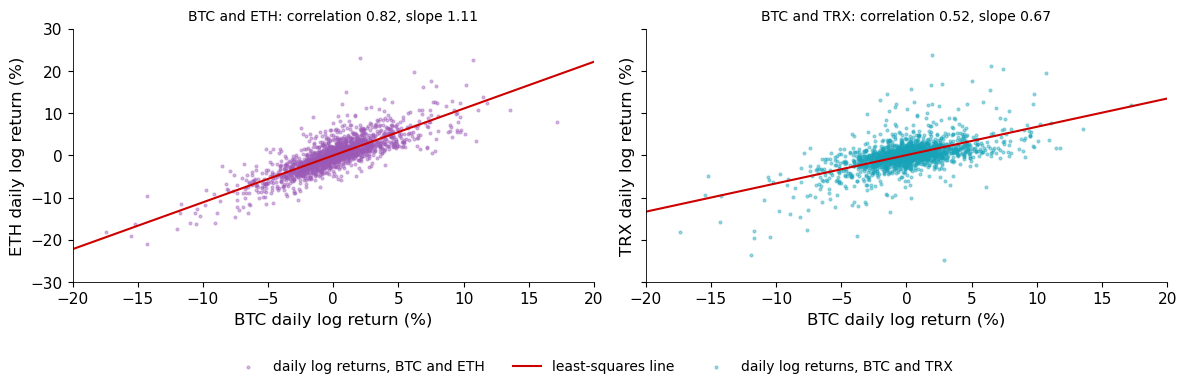

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9), sharex=True, sharey=True)
for k, (b, col) in enumerate([('ETH', ETH), ('TRX', TEAL)]):
    x, y_ = R['BTC'], R[b]
    slope, icpt = np.polyfit(x, y_, 1)
    rho = CORR.loc['BTC', b]
    print(f'BTC-{b}: correlation {rho:.2f}, slope {slope:.2f}, same direction on {100 * (np.sign(x) == np.sign(y_)).mean():.0f}% of days, '
          f'rho^2 = {rho ** 2:.2f}, distance d = {np.sqrt(2 * (1 - rho)):.2f}')
    ax[k].scatter(x, y_, s=4, color=col, alpha=0.4, label=f'daily log returns, BTC and {b}')
    xx = np.linspace(-20, 20, 50)
    ax[k].plot(xx, icpt + slope * xx, color=RED, lw=1.5, label='least-squares line' if k == 0 else None)
    ax[k].set_xlim(-20, 20); ax[k].set_ylim(-30, 30)
    ax[k].set_xlabel('BTC daily log return (%)'); ax[k].set_ylabel(f'{b} daily log return (%)')
    ax[k].set_title(f'BTC and {b}: correlation {rho:.2f}, slope {slope:.2f}', fontsize=10)
legend_at_bottom(fig, ncol=3, bottom=0.1)
save_fig(fig, 'ba_l7_pairs')

The chart shows the correlation matrix (left; red = high correlation) and the MST (right). Node size grows with the MST degree;
edge width grows with the correlation of the two coins.

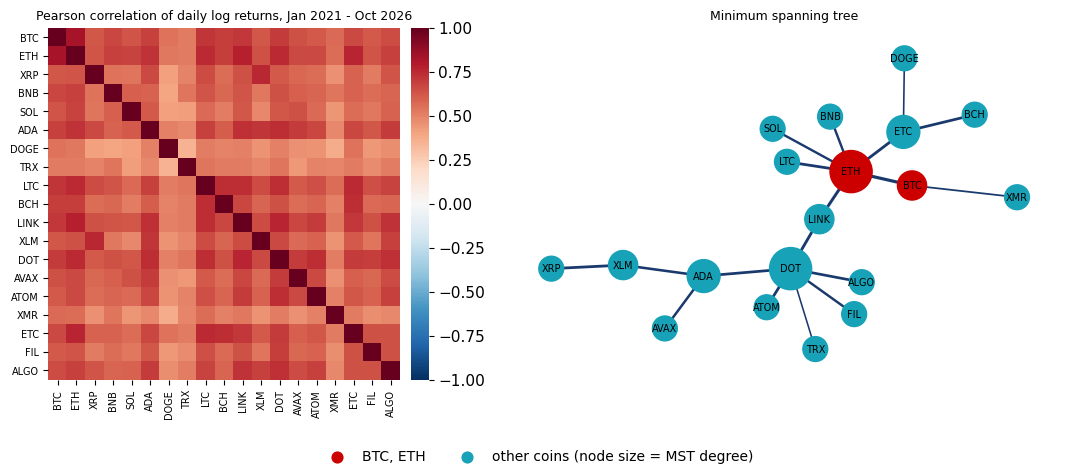

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={'width_ratios': [1, 1.05]})
im = ax[0].imshow(CORR.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax[0].set_xticks(range(len(COINS))); ax[0].set_xticklabels(COINS, rotation=90, fontsize=7)
ax[0].set_yticks(range(len(COINS))); ax[0].set_yticklabels(COINS, fontsize=7)
ax[0].set_title('Pearson correlation of daily log returns, Jan 2021 - Oct 2026', fontsize=9)
for sp in ax[0].spines.values():
    sp.set_visible(False)
cbar = fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.02); cbar.outline.set_visible(False)
pos = nx.kamada_kawai_layout(G, weight='d')
nx.draw_networkx_edges(G, pos, ax=ax[1], edge_color=BLUE, width=[1 + 4 * (G[a][b]['rho'] - 0.5) for a, b in G.edges()])
nx.draw_networkx_nodes(G, pos, ax=ax[1], node_color=[RED if n in ('BTC', 'ETH') else TEAL for n in G.nodes()],
                       node_size=[200 + 120 * deg[n] for n in G.nodes()])
nx.draw_networkx_labels(G, pos, ax=ax[1], font_size=7)
ax[1].set_title('Minimum spanning tree', fontsize=9)
ax[1].axis('off')
ax[1].scatter([], [], color=RED, s=60, label='BTC, ETH')
ax[1].scatter([], [], color=TEAL, s=60, label='other coins (node size = MST degree)')
legend_at_bottom(fig, ncol=2, bottom=0.08)
save_fig(fig, 'ba_l7_mst')

### Eigenvalues of the correlation matrix and the absorption ratio

The principal components of the correlation matrix are uncorrelated portfolios of the standardised returns; the eigenvalue $\lambda_k$ is the
variance of the $k$-th component and the eigenvalues add up to $N = 19$. The **absorption ratio** $\mathrm{AR} = \lambda_1/N$ is the share of
the total variance taken by the first component. If every pair had the same correlation $\rho$, then $\lambda_1 = 1 + (N-1)\rho$ and the other
eigenvalues would equal $1 - \rho$. The cell compares the actual eigenvalues with this equicorrelation benchmark at the mean correlation, and
the absorption ratio of each calendar year with $(1 + 18\bar\rho)/19$.

Eigenvalues: lambda_1 = 11.84, lambda_2 = 0.79; eigenvalues above 1: 1
Equicorrelation benchmark with rho = 0.60: lambda_1 = 11.74, the others 0.40
      mean correlation  absorption ratio  (1 + 18 rho)/19
2021             0.569             0.603            0.591
2022             0.725             0.743            0.739
2023             0.563             0.592            0.586
2024             0.551             0.596            0.575
2025             0.679             0.708            0.696
2026             0.607             0.648            0.627
Largest gap between the absorption ratio and the formula: 0.021


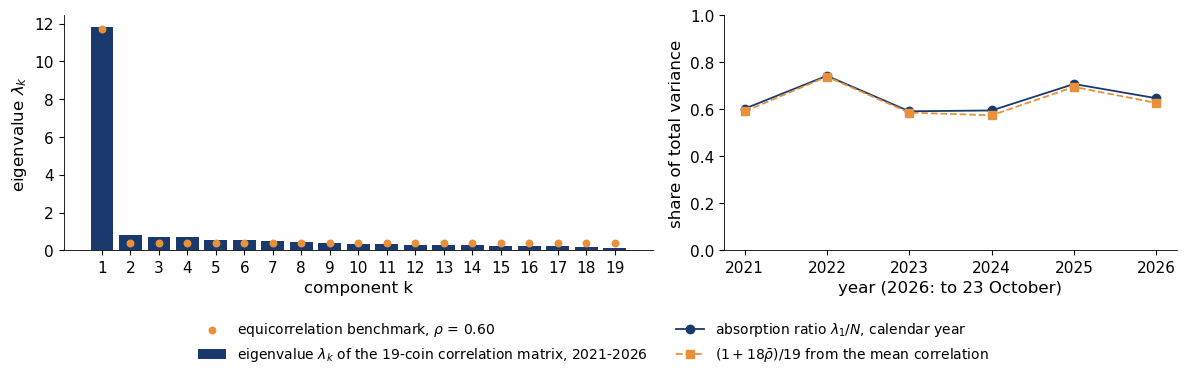

In [9]:
N_ = len(COINS)
ev = np.linalg.eigvalsh(CORR.values)[::-1]
rbar = CORR.values[iu].mean()
print(f'Eigenvalues: lambda_1 = {ev[0]:.2f}, lambda_2 = {ev[1]:.2f}; eigenvalues above 1: {(ev > 1).sum()}')
print(f'Equicorrelation benchmark with rho = {rbar:.2f}: lambda_1 = {1 + (N_ - 1) * rbar:.2f}, the others {1 - rbar:.2f}')
yr = {}
for Y in range(2021, 2027):
    c_ = R.loc[str(Y)].corr().values
    yr[Y] = {'mean correlation': c_[iu].mean(), 'absorption ratio': np.linalg.eigvalsh(c_)[-1] / N_,
             '(1 + 18 rho)/19': (1 + (N_ - 1) * c_[iu].mean()) / N_}
yr = pd.DataFrame(yr).T
print(yr.round(3).to_string())
print(f"Largest gap between the absorption ratio and the formula: {(yr['absorption ratio'] - yr['(1 + 18 rho)/19']).abs().max():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1.3, 1]})
k_ = np.arange(1, N_ + 1)
ax[0].bar(k_, ev, color=BLUE, label='eigenvalue $\\lambda_k$ of the 19-coin correlation matrix, 2021-2026')
ax[0].scatter(k_, [1 + (N_ - 1) * rbar] + [1 - rbar] * (N_ - 1), color=BTC, s=22, zorder=5, label=f'equicorrelation benchmark, $\\rho$ = {rbar:.2f}')
ax[0].set_xticks(k_); ax[0].set_xlabel('component k'); ax[0].set_ylabel('eigenvalue $\\lambda_k$')
ax[1].plot(yr.index, yr['absorption ratio'], color=BLUE, marker='o', label='absorption ratio $\\lambda_1/N$, calendar year')
ax[1].plot(yr.index, yr['(1 + 18 rho)/19'], color=BTC, marker='s', ls='--', label='$(1 + 18\\bar\\rho)/19$ from the mean correlation')
ax[1].set_ylim(0, 1); ax[1].set_xlabel('year (2026: to 23 October)'); ax[1].set_ylabel('share of total variance')
legend_at_bottom(fig, ncol=2, bottom=0.16)
save_fig(fig, 'ba_l7_eigen')

### Rolling correlation and absorption ratio, 2021–2026

A single correlation matrix averages over six years. To see how connectedness changes, the cell below re-estimates the correlation
matrix on a rolling 90-day window, moved forward 5 days at a time, and records two numbers:

* the mean pairwise correlation of the 19 coins;
* the **absorption ratio** $\mathrm{AR}_t = \lambda_1 / \sum_k \lambda_k$, where $\lambda_1 \ge \lambda_2 \ge \dots$ are the eigenvalues of the
  90-day correlation matrix. It is the share of total variance explained by the first principal component, that is, by one common factor.

The eigenvalue $\lambda_k$ is the variance of the $k$-th principal component; for a correlation matrix $\sum_k \lambda_k = N$, so AR lies between
$1/N$ and 1. Worked example: if all 19 coins had the same pairwise correlation $\rho$, then $\lambda_1 = 1 + 18\rho$ and the other eigenvalues equal
$1 - \rho$; with $\rho = 0.60$, $\mathrm{AR} = 11.8/19 = 0.62$, and with $\rho = 0.85$, $\mathrm{AR} = 0.86$.

When one factor explains 80% of the variance, holding many coins instead of one gives almost no diversification.

Mean pairwise correlation (90-day window): lowest 0.363 on 2021-04-21, highest 0.854 on 2021-08-14, last 0.535 on 2026-10-22
Absorption ratio: average over all windows 0.682, last window (ending 2026-10-22) 0.589


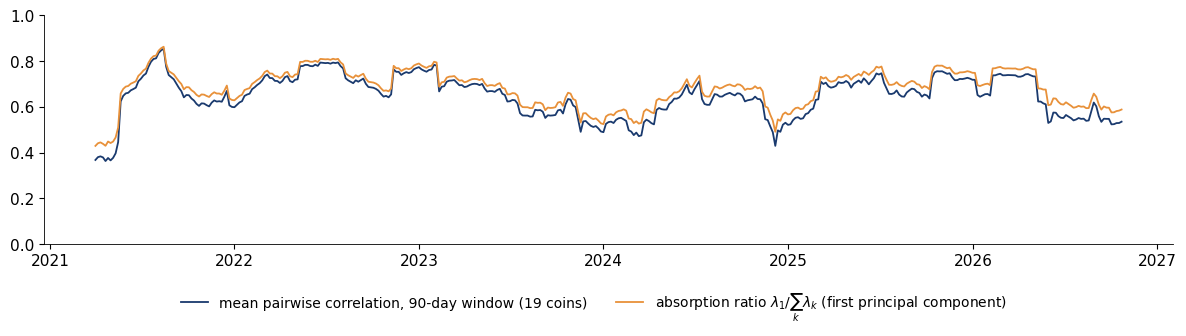

In [10]:
W = 90
mc, ar = {}, {}
for k in range(W, len(R) + 1, 5):
    x = R.iloc[k - W:k]
    c = x.corr().values
    mc[x.index[-1]] = c[iu].mean()
    ev = np.linalg.eigvalsh(c)[::-1]
    ar[x.index[-1]] = ev[0] / ev.sum()
mc, ar = pd.Series(mc), pd.Series(ar)
print(f'Mean pairwise correlation (90-day window): lowest {mc.min():.3f} on {mc.idxmin().date()}, '
      f'highest {mc.max():.3f} on {mc.idxmax().date()}, last {mc.iloc[-1]:.3f} on {mc.index[-1].date()}')
print(f'Absorption ratio: average over all windows {ar.mean():.3f}, last window (ending {ar.index[-1].date()}) {ar.iloc[-1]:.3f}')

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(mc.index, mc, color=BLUE, lw=1.3, label='mean pairwise correlation, 90-day window (19 coins)')
ax.plot(ar.index, ar, color=BTC, lw=1.3, label=r'absorption ratio $\lambda_1 / \sum_k \lambda_k$ (first principal component)')
ax.set_ylim(0, 1)
legend_at_bottom(fig, ncol=2, bottom=0.14)
save_fig(fig, 'ba_l7_connect')

### Spillovers: Diebold–Yilmaz

Correlation is symmetric and contemporaneous. Diebold and Yilmaz measure *directional* spillovers from a vector autoregression (VAR)
on $N$ return series,

$$ \mathbf r_t = \sum_{l=1}^{p}\Phi_l \mathbf r_{t-l} + \boldsymbol\varepsilon_t, \qquad \text{moving-average (MA) form } \mathbf r_t = \sum_{h \geq 0} A_h \boldsymbol\varepsilon_{t-h}, \quad \Sigma = V(\boldsymbol\varepsilon_t). $$

The generalised forecast-error variance decomposition (FEVD) of Pesaran and Shin at horizon $H$ is

$$ \theta_{ij}(H) = \frac{\sigma_{jj}^{-1}\sum_{h=0}^{H-1}\big(\mathbf e_i' A_h \Sigma \mathbf e_j\big)^2}{\sum_{h=0}^{H-1}\mathbf e_i' A_h \Sigma A_h' \mathbf e_i}, \qquad \tilde\theta_{ij} = \frac{\theta_{ij}}{\sum_j \theta_{ij}} . $$

$\tilde\theta_{ij}$ is the share (between 0 and 1) of coin $i$'s $H$-day forecast-error variance due to shocks in coin $j$; unlike a Cholesky decomposition,
it does not depend on the ordering of the variables. The spillover indices, in %, multiply the sums of shares by 100:

$$ S = \frac{100}{N}\sum_{i \neq j}\tilde\theta_{ij}, \qquad \mathrm{TO}_j = 100\sum_{i \neq j}\tilde\theta_{ij}, \qquad \mathrm{FROM}_i = 100\sum_{j \neq i}\tilde\theta_{ij}, \qquad \mathrm{NET}_i = \mathrm{TO}_i - \mathrm{FROM}_i . $$

TO$_j$ is what coin $j$ sends to all others; FROM$_i$ is what coin $i$ receives from all others.

The cell below fits a VAR to 8 large coins, with the lag order $p$ chosen by the Akaike information criterion (AIC, at most 5 lags), and $H = 10$ days.
In the table, the row is the **receiver** (the coin whose variance is explained) and the column the **source** of the shocks. For example, the cell in
row BTC and column ETH is the share of BTC's forecast-error variance due to ETH shocks, a spillover ETH → BTC.

In [11]:
SUB = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'LTC']


def gfevd(res, H=10):
    """Generalised FEVD (Pesaran-Shin), rows normalised to 1."""
    Sig = np.asarray(res.sigma_u)
    A = res.ma_rep(H - 1)                                        # A_0 .. A_{H-1}
    k = Sig.shape[0]
    th = np.zeros((k, k))
    for i in range(k):
        den = sum(A[h][i] @ Sig @ A[h][i] for h in range(H))
        for j in range(k):
            th[i, j] = sum((A[h][i] @ Sig[:, j]) ** 2 for h in range(H)) / Sig[j, j] / den
    return th / th.sum(axis=1, keepdims=True)


Y = R[SUB]
vr = VAR(Y).fit(maxlags=5, ic='aic')
TH = gfevd(vr)
total = 100 * (TH.sum() - np.trace(TH)) / len(SUB)
to_ = 100 * (TH.sum(axis=0) - np.diag(TH))
from_ = 100 * (TH.sum(axis=1) - np.diag(TH))
net = pd.Series(to_ - from_, index=SUB)
tab = pd.DataFrame(100 * TH, index=SUB, columns=SUB)
tab['FROM'] = from_
tab.loc['TO'] = list(to_) + [total]
tab.loc['NET'] = list(net) + [np.nan]
print(f'VAR lag order chosen by AIC: {vr.k_ar}; forecast horizon H = 10 days')
print('Spillover table (%), row = receiver, column = source of the shocks:')
print(tab.round(1).to_string())
print(f'\nTotal spillover index S = mean of the FROM column = {total:.1f}%')
print(f"Worked check: NET(ETH) = TO(ETH) - FROM(ETH) = {to_[1]:.1f} - {from_[1]:.1f} = {net['ETH']:+.1f}")
print(f"Reading a cell: {tab.loc['BTC', 'ETH']:.1f}% of BTC's 10-day forecast-error variance is due to ETH shocks (ETH -> BTC)")
print(f"Largest net receiver: {net.idxmin()} (NET {net.min():+.1f}), with FROM {from_[SUB.index(net.idxmin())]:.1f} "
      f"(lowest FROM: {SUB[int(np.argmin(from_))]}) and TO {to_[SUB.index(net.idxmin())]:.1f}")

VAR lag order chosen by AIC: 5; forecast horizon H = 10 days
Spillover table (%), row = receiver, column = source of the shocks:
       BTC   ETH   XRP   BNB   SOL   ADA  DOGE   LTC  FROM
BTC   23.3  16.0   9.4  10.6  10.0  11.3   7.3  12.0  76.7
ETH   15.3  22.5   9.5  10.5  10.9  11.8   6.9  12.5  77.5
XRP   11.2  11.8  28.1   9.0   8.6  13.0   5.9  12.4  71.9
BNB   12.7  13.3   8.9  28.4  10.4  10.0   4.9  11.3  71.6
SOL   12.1  13.8   8.5  10.5  28.3  11.6   5.7   9.4  71.7
ADA   12.1  13.2  11.5   8.7  10.3  25.0   7.2  12.0  75.0
DOGE  11.4  11.1   7.3   6.0   7.1  10.4  36.4  10.2  63.6
LTC   12.8  14.0  11.0   9.9   8.3  11.9   7.1  25.0  75.0
TO    87.7  93.2  66.1  65.4  65.7  80.0  45.0  80.0  72.9
NET   11.0  15.7  -5.8  -6.3  -6.0   5.0 -18.6   5.0   NaN

Total spillover index S = mean of the FROM column = 72.9%
Worked check: NET(ETH) = TO(ETH) - FROM(ETH) = 93.2 - 77.5 = +15.7
Reading a cell: 16.0% of BTC's 10-day forecast-error variance is due to ETH shocks (ETH -> BTC)


### Spillovers through time

The total spillover index is re-estimated on rolling 200-day windows, moved forward 10 days at a time, with a VAR(2) in every window
(a fixed lag keeps the windows comparable). The right panel shows the full-sample NET spillovers: positive values are net transmitters of shocks,
negative values net receivers. Dotted lines mark the Terra collapse (May 2022), the FTX collapse (November 2022) and the launch of the spot
Bitcoin exchange-traded funds (ETFs, January 2024).

Rolling total spillover index (%): lowest 65.2 on 2021-07-20, highest 83.5 on 2026-05-25, last 80.4 on 2026-10-22


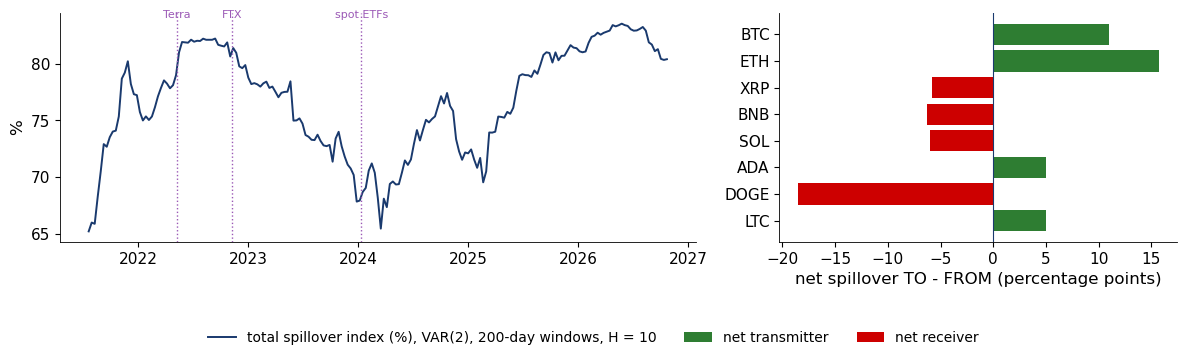

In [12]:
roll = {}
for k in range(200, len(Y) + 1, 10):
    y = Y.iloc[k - 200:k]
    th = gfevd(VAR(y).fit(2))
    roll[y.index[-1]] = 100 * (th.sum() - np.trace(th)) / len(SUB)
roll = pd.Series(roll)
print(f'Rolling total spillover index (%): lowest {roll.min():.1f} on {roll.idxmin().date()}, '
      f'highest {roll.max():.1f} on {roll.idxmax().date()}, last {roll.iloc[-1]:.1f} on {roll.index[-1].date()}')

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(roll.index, roll, color=BLUE, lw=1.4, label='total spillover index (%), VAR(2), 200-day windows, H = 10')
for d0, lab in [('2022-05-09', 'Terra'), ('2022-11-08', 'FTX'), ('2024-01-11', 'spot ETFs')]:
    ax[0].axvline(pd.Timestamp(d0), color=ETH, ls=':', lw=1)
    ax[0].text(pd.Timestamp(d0), roll.max() + 0.5, lab, fontsize=8, color=ETH, ha='center')
ax[0].set_ylabel('%')
ax[1].barh(net.index[::-1], net.values[::-1], color=[GREEN if v > 0 else RED for v in net.values[::-1]])
ax[1].axvline(0, color=BLUE, lw=0.8)
ax[1].set_xlabel('net spillover TO - FROM (percentage points)')
for col_, lb_ in [(GREEN, 'net transmitter'), (RED, 'net receiver')]:
    ax[1].bar([0], [0], color=col_, label=lb_, width=0)
legend_at_bottom(fig, ncol=3, bottom=0.14)
save_fig(fig, 'ba_l7_spill')

## 2. Are cryptos an asset class?

### Classifying assets by their statistical "phenotype"

Following the idea of Pele et al. (2023), each asset is described by the stylised facts of its daily log returns (2021–2026), and we ask
whether cryptos form a group of their own. Six features per asset:

* annualised volatility (daily standard deviation times $\sqrt{365}$ for coins, which trade every day, and $\sqrt{252}$ for the other assets;
  for gold, FX and the S&P 500 only Monday–Friday closes are used, with repeated closes removed, because the data contain thin weekend sessions);
* skewness and the logarithm of kurtosis;
* the Hill estimate of the tail index on the largest 5% of absolute returns (smaller = heavier tails);
* the lag-1 autocorrelation (ACF) of $|r_t|$, a measure of volatility clustering;
* the 1% quantile of returns in units of their standard deviation.

The 33 assets are the 19 coins, 6 equities (the S&P 500 index and five stocks), long Treasuries (the TLT fund), gold, silver, oil and
four foreign-exchange (FX) rates. Each feature is standardised across the 33 assets (mean 0, standard deviation 1); the return series themselves
are not rescaled, and volatility remains one of the six features. The standardised features are summarised by principal component analysis (PCA)
and grouped by $k$-means clustering with $k = 3$ (each asset is assigned to the nearest of three cluster centres, chosen to minimise
within-cluster distances). A second run drops volatility and keeps only the five shape features, to check whether the grouping comes from shape or from scale.

In [13]:
TRAD = {'S&P 500': 'GSPC.INDX', 'Apple': 'AAPL.US', 'Microsoft': 'MSFT.US', 'JPMorgan': 'JPM.US', 'Exxon': 'XOM.US', 'Coca-Cola': 'KO.US',
        'Treasuries (TLT)': 'TLT.US', 'Gold': 'XAUUSD.FOREX', 'Silver (SLV)': 'SLV.US', 'Oil (USO)': 'USO.US',
        'EUR/USD': 'EURUSD.FOREX', 'GBP/USD': 'GBPUSD.FOREX', 'USD/JPY': 'USDJPY.FOREX', 'USD/CHF': 'USDCHF.FOREX'}
CLS = {**{c: 'crypto' for c in COINS}, 'S&P 500': 'equity', 'Apple': 'equity', 'Microsoft': 'equity', 'JPMorgan': 'equity', 'Exxon': 'equity',
       'Coca-Cola': 'equity', 'Treasuries (TLT)': 'bond', 'Gold': 'commodity', 'Silver (SLV)': 'commodity', 'Oil (USO)': 'commodity',
       'EUR/USD': 'FX', 'GBP/USD': 'FX', 'USD/JPY': 'FX', 'USD/CHF': 'FX'}


def weekdays(s, sym):
    """Course convention for gold, FX and indices: Monday-Friday closes, repeated closes removed (EODHD has thin weekend sessions)."""
    if sym.endswith(('.FOREX', '.INDX')):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


series = {**{c: P[c] for c in COINS}, **{k: weekdays(px(v), v).loc['2021-01-01':] for k, v in TRAD.items()}}


def hill(x, frac=0.05):
    """Hill estimator of the tail index from the largest frac of |x|."""
    a = np.sort(np.abs(x))[::-1]
    k = int(frac * len(a))
    return 1 / np.mean(np.log(a[:k] / a[k]))


feat = {}
for k, s in series.items():
    r = 100 * np.log(s).diff().dropna()
    feat[k] = dict(vol=r.std() * np.sqrt(365 if CLS[k] == 'crypto' else 252), skew=stats.skew(r), log_kurt=np.log(stats.kurtosis(r) + 3),
                   tail_index=hill(r.values), acf_abs=r.abs().autocorr(1), q01_sd=np.quantile(r, 0.01) / r.std())
F = pd.DataFrame(feat).T
Z = StandardScaler().fit_transform(F.values)
pca = PCA(n_components=3).fit(Z)
S = pca.transform(Z)
km = KMeans(n_clusters=3, n_init=50, random_state=0).fit(Z)
lab = pd.Series(km.labels_, index=F.index)

print('Share of variance explained by the principal components (%):', np.round(100 * pca.explained_variance_ratio_, 1))
print('\nLoadings of the six standardised features on PC1 and PC2:')
print(pd.DataFrame(pca.components_[:2].T, index=F.columns, columns=['PC1', 'PC2']).round(2).to_string())
print('\nNumber of assets of each class in each k-means cluster:')
print(pd.crosstab(pd.Series(CLS).reindex(F.index).rename('class'), lab.rename('cluster')).to_string())
for g in sorted(lab.unique()):
    print(f'\ncluster {g}:', ', '.join(lab.index[lab == g]))
print('\nFeatures (vol = annualised volatility in %, tail_index = Hill estimate, q01_sd = 1% quantile in sd units):')
print(F.round(2).to_string())

# robustness: shape only (volatility dropped), same standardisation, PCA and k-means
Fs = F.drop(columns='vol')
Zs = StandardScaler().fit_transform(Fs.values)
pcs = PCA(n_components=3).fit(Zs)
labs = pd.Series(KMeans(n_clusters=3, n_init=50, random_state=0).fit(Zs).labels_, index=F.index)
print('\nShape only (volatility dropped): share of variance of the principal components (%):', np.round(100 * pcs.explained_variance_ratio_, 1))
print(pd.crosstab(pd.Series(CLS).reindex(F.index).rename('class'), labs.rename('cluster')).to_string())
for g in sorted(labs.unique()):
    print(f'cluster {g}:', ', '.join(labs.index[labs == g]))

Share of variance explained by the principal components (%): [62.7 18.5  7.6]

Loadings of the six standardised features on PC1 and PC2:
             PC1   PC2
vol         0.40 -0.21
skew        0.39  0.46
log_kurt    0.46 -0.15
tail_index -0.44  0.38
acf_abs     0.46 -0.14
q01_sd      0.27  0.75

Number of assets of each class in each k-means cluster:
cluster    0   1  2
class              
FX         4   0  0
bond       1   0  0
commodity  3   0  0
crypto     4  14  1
equity     6   0  0

cluster 0: BTC, ETH, LTC, LINK, S&P 500, Apple, Microsoft, JPMorgan, Exxon, Coca-Cola, Treasuries (TLT), Gold, Silver (SLV), Oil (USO), EUR/USD, GBP/USD, USD/JPY, USD/CHF

cluster 1: XRP, BNB, SOL, ADA, TRX, BCH, XLM, DOT, AVAX, ATOM, XMR, ETC, FIL, ALGO

cluster 2: DOGE

Features (vol = annualised volatility in %, tail_index = Hill estimate, q01_sd = 1% quantile in sd units):
                     vol  skew  log_kurt  tail_index  acf_abs  q01_sd
BTC                56.74 -0.13      1.97        3.56  

### Volatility and tails of 33 assets

Two of the six features side by side: annualised volatility (horizontal) and the Hill tail index (vertical; a lower index means a heavier tail).

Volatility: coins 57% (BTC) to 132% (DOGE), median coin 95%; traditional assets up to 37% (Silver (SLV))
Hill tail index: coins 2.12 (TRX) to 3.66 (LINK); traditional 3.07 (Silver (SLV)) to 5.10 (Exxon); BTC 3.56, S&P 500 3.44


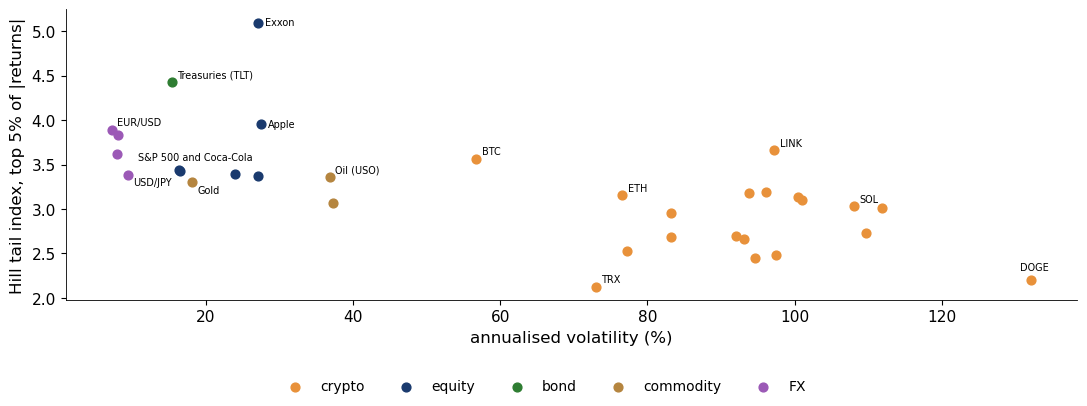

In [14]:
cls_ = pd.Series(CLS).reindex(F.index)
trad = F.index[cls_ != 'crypto']
print(f"Volatility: coins {F.loc[COINS, 'vol'].min():.0f}% ({F.loc[COINS, 'vol'].idxmin()}) to {F.loc[COINS, 'vol'].max():.0f}% "
      f"({F.loc[COINS, 'vol'].idxmax()}), median coin {F.loc[COINS, 'vol'].median():.0f}%; traditional assets up to {F.loc[trad, 'vol'].max():.0f}% ({F.loc[trad, 'vol'].idxmax()})")
print(f"Hill tail index: coins {F.loc[COINS, 'tail_index'].min():.2f} ({F.loc[COINS, 'tail_index'].idxmin()}) to {F.loc[COINS, 'tail_index'].max():.2f} "
      f"({F.loc[COINS, 'tail_index'].idxmax()}); traditional {F.loc[trad, 'tail_index'].min():.2f} ({F.loc[trad, 'tail_index'].idxmin()}) to "
      f"{F.loc[trad, 'tail_index'].max():.2f} ({F.loc[trad, 'tail_index'].idxmax()}); BTC {F.loc['BTC', 'tail_index']:.2f}, S&P 500 {F.loc['S&P 500', 'tail_index']:.2f}")
fig, ax = plt.subplots(figsize=(11, 4.1))
for cl, col in {'crypto': BTC, 'equity': BLUE, 'bond': GREEN, 'commodity': GOLD, 'FX': ETH}.items():
    m = (cls_ == cl).values
    ax.scatter(F['vol'][m], F['tail_index'][m], color=col, s=40, label=cl)
LBL = {'BTC': (4, 3), 'ETH': (4, 3), 'DOGE': (-8, 7), 'SOL': (4, 3), 'TRX': (4, 3), 'LINK': (4, 3), 'S&P 500': (-30, 7),
       'Gold': (4, -8), 'Oil (USO)': (4, 3), 'EUR/USD': (4, 3), 'USD/JPY': (4, -8), 'Treasuries (TLT)': (4, 3), 'Exxon': (5, -2), 'Apple': (5, -2)}
for k, off in LBL.items():
    ax.annotate('S&P 500 and Coca-Cola' if k == 'S&P 500' else k, (F.loc[k, 'vol'], F.loc[k, 'tail_index']), fontsize=7, xytext=off, textcoords='offset points')
ax.set_xlabel('annualised volatility (%)'); ax.set_ylabel('Hill tail index, top 5% of |returns|')
legend_at_bottom(fig, ncol=5, bottom=0.1)
save_fig(fig, 'ba_l7_features')

### Classification map of 33 assets

Each asset is placed by its scores on the first two principal components; colours give the conventional asset class.

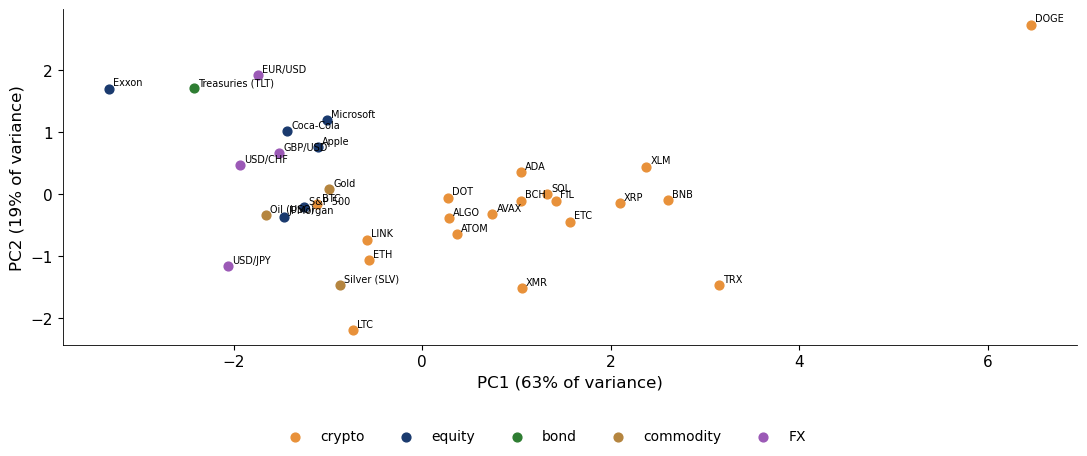

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.6))
cc = {'crypto': BTC, 'equity': BLUE, 'bond': GREEN, 'commodity': GOLD, 'FX': ETH}
for cl, col in cc.items():
    m = np.array([CLS[k] == cl for k in F.index])
    ax.scatter(S[m, 0], S[m, 1], color=col, s=40, label=cl)
for i, k in enumerate(F.index):
    ax.annotate(k, (S[i, 0], S[i, 1]), fontsize=7, xytext=(3, 2), textcoords='offset points')
ax.set_xlabel(f'PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}% of variance)')
ax.set_ylabel(f'PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}% of variance)')
legend_at_bottom(fig, ncol=5, bottom=0.1)
save_fig(fig, 'ba_l7_classes')

### Worked example: where Bitcoin sits on PC1

The PC1 score of an asset is $\sum_k w_k z_k$: each feature is standardised across the 33 assets, $z = (x - \text{mean})/\text{sd}$ (the
standard deviation with divisor 33, as in `StandardScaler`), and weighted by its PC1 loading $w_k$.

In [16]:
sc = StandardScaler().fit(F.values)
we = pd.DataFrame({'BTC value': F.loc['BTC'], 'mean (33 assets)': sc.mean_, 'sd (33 assets)': sc.scale_}, index=F.columns)
we['z of BTC'] = (we['BTC value'] - we['mean (33 assets)']) / we['sd (33 assets)']
we['PC1 loading w'] = pca.components_[0]
we['w x z'] = we['PC1 loading w'] * we['z of BTC']
print(we.round(3).to_string())
pc1 = pd.Series(S[:, 0], index=F.index)
print(f"\nPC1 score of BTC = sum of w x z = {we['w x z'].sum():.2f} (PCA: {pc1['BTC']:.2f}); S&P 500 {pc1['S&P 500']:.2f}, "
      f"ETH {pc1['ETH']:.2f}, DOGE {pc1['DOGE']:+.2f}; BTC ranks {int((pc1 > pc1['BTC']).sum()) + 1} of {len(pc1)}")

            BTC value  mean (33 assets)  sd (33 assets)  z of BTC  PC1 loading w  w x z
vol            56.744            62.310          38.934    -0.143          0.404 -0.058
skew           -0.128             0.208           1.301    -0.258          0.390 -0.101
log_kurt        1.971             2.469           0.726    -0.687          0.456 -0.314
tail_index      3.562             3.215           0.608     0.570         -0.438 -0.250
acf_abs         0.154             0.192           0.076    -0.497          0.462 -0.230
q01_sd         -2.754            -2.634           0.198    -0.607          0.266 -0.162

PC1 score of BTC = sum of w x z = -1.11 (PCA: -1.11); S&P 500 -1.25, ETH -0.57, DOGE +6.46; BTC ranks 23 of 33


### The paper: cryptos as a separate asset class

Pele, Wesselhöfft, Härdle, Kolossiatis and Yatracos (2023, *European Journal of Finance*) use 906 assets (234 cryptos, 635 stocks, 13 FX rates,
17 commodities, 5 bonds, 2 real-estate indices), daily, January 2014 – November 2020, and 24 indicators per asset: variance, skewness,
kurtosis, the stable-distribution parameters $\alpha$ and $\gamma$, left and right quantiles and conditional tail expectations (CTE) at
0.5–5%, the lag-1 autocorrelation, the Hurst exponent and the fractional-integration parameter $d$ of a FIGARCH model.

* Factor analysis gives three factors that explain 88% of the variance: a **tail** factor (76%), a **memory** factor (6%) and a **moment** factor (6%).
* A logit of $P(\text{crypto})$ on the tail factor has Nagelkerke $\tilde R^2 = 0.992$; a support vector machine (SVM) on two factors
  classifies 99.56% of the assets correctly (only BTC and USDT are misclassified).
* Averages by class: crypto variance is about 60 times that of stocks, and the stable tail parameter is 1.34 for cryptos against 1.60 for stocks.
* Returns are daily, in decimals: the crypto 1% quantile of −0.366 is a daily loss of 36.6% at the 1% level, averaged over 234 cryptos.

How to read the indicators:

* stable $\alpha \in (0, 2]$ is the tail parameter of a stable distribution fitted to *all* returns; $\alpha = 2$ is the Normal, $\alpha < 2$ means
  infinite variance, and smaller values mean heavier tails. The Hill tail index of Lecture 2 uses only the largest returns and is usually 2–4 for
  financial returns. The two come from different models and parts of the distribution, so their values are not comparable;
* Hurst exponent $H \in (0, 1)$: memory in returns; 0.5 = none, above 0.5 = persistent trends, below 0.5 = mean reversion;
* FIGARCH $d \in [0, 1]$: memory in volatility; $d = 0$ is GARCH (shocks fade geometrically), larger $d$ = shocks fade more slowly (hyperbolically);
* factor loading: correlation between an indicator and a factor, from −1 to 1;
* Kaiser–Meyer–Olkin (KMO) measure $\in [0, 1]$: how much of the indicators' correlation is common to all of them; above 0.8 = well suited to factor analysis;
* Nagelkerke $\tilde R^2 \in [0, 1]$: a pseudo-$R^2$ of a logit, rescaled so that 1 = perfect classification.

| | Cryptos | Stocks | Bonds | FX | Commodities | Real estate |
|---|---:|---:|---:|---:|---:|---:|
| variance $\times 10^3$ | 26.442 | 0.400 | 0.745 | 0.028 | 0.388 | 0.146 |
| stable $\alpha$ | 1.342 | 1.602 | 1.460 | 1.722 | 1.662 | 1.696 |
| 1% quantile | −0.366 | −0.054 | −0.057 | −0.013 | −0.050 | −0.034 |
| CTE 1% | −0.564 | −0.085 | −0.097 | −0.017 | −0.074 | −0.052 |
| skewness | 0.686 | −0.560 | −0.829 | −0.937 | −0.495 | −1.142 |
| FIGARCH $d$ | 0.553 | 0.289 | 0.545 | 0.407 | 0.426 | 0.510 |

In the update above, volatility is one of six standardised features, so it does not dominate the distance between assets; with volatility
dropped (shape features only), BTC and ETH still group with the traditional assets in 2021–2026, consistent with the paper's finding that BTC
lies at the border of the crypto class.

## 3. Event studies: Ethereum upgrades

### The market-model event study

The normal return of Ether (ETH) is predicted by a market model estimated on days $[-250, -31]$ before the event:

$$ R_t = \alpha + \beta R_{m,t} + u_t, \qquad \mathrm{AR}_t = R_t - \hat\alpha - \hat\beta R_{m,t}, \qquad \mathrm{CAR}(\tau_1, \tau_2) = \sum_{t=\tau_1}^{\tau_2}\mathrm{AR}_t . $$

$\mathrm{AR}_t$ is the abnormal return and CAR the cumulative abnormal return over the event window $[\tau_1, \tau_2]$ (day 0 = event day).
For one event, $t = \mathrm{CAR}(\tau_1,\tau_2) / \sqrt{L\,\hat\sigma_u^2}$ with $L = \tau_2 - \tau_1 + 1$. Across $N$ events, the cross-sectional (CS)
test and the Boehmer–Musumeci–Poulsen (BMP) test on standardised CARs (SCAR) are

$$ t_{CS} = \frac{\overline{\mathrm{CAR}}}{s_{\mathrm{CAR}}/\sqrt N}, \qquad \mathrm{SCAR}_e = \frac{\mathrm{CAR}_e}{\hat\sigma_{u,e}\sqrt L}, \qquad t_{BMP} = \frac{\overline{\mathrm{SCAR}}}{s_{\mathrm{SCAR}}/\sqrt N} . $$

The sign test compares the number of positive CARs with a $\mathrm{Bin}(N, 0.5)$ distribution.

Two simplifications. The one-event $t$ ignores the estimation error of $\hat\alpha$ and $\hat\beta$; the full variance of a CAR over $L$ days is
$\hat\sigma_u^2\,(L + \boldsymbol\iota' X^*(X'X)^{-1}X^{*\prime}\boldsymbol\iota)$, with $X$ the estimation-window regressors and $X^*$ those of the event window
(MacKinlay, 1997). The BMP statistic here standardises by $\hat\sigma_u\sqrt L$, without that forecast-error correction. All cross-event tests also
assume independent events; the cell checks overlapping windows.

Design: the market return $R_{m,t}$ is an equal-weighted index of 11 other coins with data since 2019. There are 13 upgrade families,
from Istanbul (2019) to Fusaka (2025), each with two dates: the formal schedule (when the date is fixed) and the implementation.
Event windows: $[-1, +1]$ and $[0, +5]$.

In [17]:
EV = [('Istanbul', '2019-11-20', '2019-12-08'), ('Muir Glacier', '2019-11-22', '2020-01-02'), ('Beacon Chain', '2020-11-04', '2020-12-01'),
      ('Berlin', '2021-03-08', '2021-04-15'), ('London', '2021-07-15', '2021-08-05'), ('Altair', '2021-10-05', '2021-10-27'),
      ('Arrow Glacier', '2021-11-10', '2021-12-09'), ('Gray Glacier', '2022-06-16', '2022-06-30'), ('Merge', '2022-08-24', '2022-09-15'),
      ('Shapella', '2023-03-28', '2023-04-12'), ('Dencun', '2024-02-27', '2024-03-13'), ('Pectra', '2025-04-23', '2025-05-07'),
      ('Fusaka', '2025-11-06', '2025-12-03')]
MKT = ['BTC', 'XRP', 'BNB', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'XMR']

RE = (100 * np.log(pd.DataFrame({c: px(f'{c}-USD.CC') for c in ['ETH'] + MKT}))).diff().loc['2018-06-01':].dropna()
r_eth, r_m = RE['ETH'], RE[MKT].mean(axis=1)
idx = {d: i for i, d in enumerate(RE.index)}
rows, paths = [], {}
for name, sd, imp in EV:
    for stage, d0 in [('schedule', sd), ('implementation', imp)]:
        i0 = idx[pd.Timestamp(d0)]
        est = slice(i0 - 250, i0 - 30)                              # days -250 .. -31
        X = np.column_stack([np.ones(220), r_m.iloc[est].values]); y = r_eth.iloc[est].values
        b = np.linalg.lstsq(X, y, rcond=None)[0]
        e = y - X @ b
        s2 = e @ e / (len(y) - 2)
        arr = r_eth.iloc[i0 - 10:i0 + 11].values - (b[0] + b[1] * r_m.iloc[i0 - 10:i0 + 11].values)   # days -10 .. +10
        car11, car05 = arr[9:12].sum(), arr[10:16].sum()
        XtXi = np.linalg.inv(X.T @ X)
        xs = np.column_stack([np.ones(3), r_m.iloc[i0 - 1:i0 + 2].values]).sum(axis=0)   # event-window regressors, days -1 .. +1
        v_full = s2 * (3 + xs @ XtXi @ xs)                            # variance of CAR[-1,+1] with estimation error
        rows.append(dict(event=name, stage=stage, date=d0, beta=b[1], resid_sd=np.sqrt(s2), CAR_m1p1=car11, t_m1p1=car11 / np.sqrt(3 * s2),
                         t_full_m1p1=car11 / np.sqrt(v_full), CAR_0p5=car05, t_0p5=car05 / np.sqrt(6 * s2)))
        paths[(name, stage)] = np.cumsum(arr)
T = pd.DataFrame(rows)
print('Market model and CARs (%) for each upgrade; CAR_m1p1 = CAR[-1,+1], CAR_0p5 = CAR[0,+5], t = t-statistic of one event:')
print(T[T.stage == 'implementation'].drop(columns='stage').round(2).to_string(index=False))
rt_ = T.t_m1p1 / T.t_full_m1p1
print(f'\nSimplified t / full t, CAR[-1,+1]: from {rt_.min():.3f} to {rt_.max():.3f} (the simplified |t| is at most {100 * (rt_.max() - 1):.1f}% too large)')
ev_days = sorted((pd.Timestamp(d), f'{n} {st}') for n, sd, im in EV for st, d in [('schedule', sd), ('implementation', im)])
for (d1, n1), (d2, n2) in zip(ev_days[:-1], ev_days[1:]):
    if (d2 - d1).days <= 6:
        print(f'Overlapping event windows: {n1} ({d1.date()}) and {n2} ({d2.date()})')
n_cont = sum(any(-250 <= idx[e2] - idx[e1] <= -31 for e2, _ in ev_days) for e1, _ in ev_days)
print(f'Event dates whose estimation window [-250, -31] contains another event day: {n_cont} of {len(ev_days)}')
print(f"\nBeta of ETH to the coin index (all 26 dates): from {T.beta.min():.2f} ({T.event[T.beta.idxmin()]}) to "
      f"{T.beta.max():.2f} ({T.event[T.beta.idxmax()]}); residual sd from {T.resid_sd.min():.1f}% to {T.resid_sd.max():.1f}% a day")

Market model and CARs (%) for each upgrade; CAR_m1p1 = CAR[-1,+1], CAR_0p5 = CAR[0,+5], t = t-statistic of one event:
        event       date  beta  resid_sd  CAR_m1p1  t_m1p1  t_full_m1p1  CAR_0p5  t_0p5
     Istanbul 2019-12-08  1.02      1.84      0.39    0.12         0.12     0.23   0.05
 Muir Glacier 2020-01-02  1.02      1.77     -0.31   -0.10        -0.10    -4.51  -1.04
 Beacon Chain 2020-12-01  1.11      1.80      1.28    0.41         0.41     3.46   0.78
       Berlin 2021-04-15  0.86      3.20     -9.91   -1.79        -1.76    -9.19  -1.17
       London 2021-08-05  0.80      3.72      8.67    1.34         1.34     2.98   0.33
       Altair 2021-10-27  0.83      3.00      4.35    0.84         0.83     3.84   0.52
Arrow Glacier 2021-12-09  0.82      2.89     -4.27   -0.85        -0.84    -8.25  -1.16
 Gray Glacier 2022-06-30  0.90      1.80     -4.59   -1.48        -1.47     2.94   0.67
        Merge 2022-09-15  1.05      2.08    -11.13   -3.09        -3.06   -18.50  -3.63
  

### Worked example: the Merge, step by step

The cell recomputes the market model of the Merge implementation date (15 September 2022) and its abnormal returns on days $-1$, $0$ and $+1$.

In [18]:
i0 = idx[pd.Timestamp('2022-09-15')]
est = slice(i0 - 250, i0 - 30)
X = np.column_stack([np.ones(220), r_m.iloc[est].values]); y_ = r_eth.iloc[est].values
(a_hat, b_hat) = np.linalg.lstsq(X, y_, rcond=None)[0]
s_u = np.sqrt(((y_ - X @ [a_hat, b_hat]) ** 2).sum() / 218)
print(f'alpha = {a_hat:.3f}%, beta = {b_hat:.3f}, residual sd = {s_u:.2f}%')
mg = pd.DataFrame({'ETH return R': r_eth.iloc[i0 - 1:i0 + 2], 'index return Rm': r_m.iloc[i0 - 1:i0 + 2]})
mg['normal return a + b Rm'] = a_hat + b_hat * mg['index return Rm']
mg['AR = R - normal'] = mg['ETH return R'] - mg['normal return a + b Rm']
print(mg.round(2).to_string())
car = mg['AR = R - normal'].sum()
print(f'CAR[-1,+1] = {car:.2f}%; standard error = {s_u:.2f} x sqrt(3) = {s_u * np.sqrt(3):.2f}%; t = {car / (s_u * np.sqrt(3)):.2f}')

alpha = 0.064%, beta = 1.054, residual sd = 2.08%
            ETH return R  index return Rm  normal return a + b Rm  AR = R - normal
date                                                                              
2022-09-14          3.36             1.66                    1.81             1.54
2022-09-15        -10.51            -2.85                   -2.94            -7.56
2022-09-16         -2.70             2.22                    2.40            -5.10
CAR[-1,+1] = -11.13%; standard error = 2.08 x sqrt(3) = 3.61%; t = -3.09


The next cell aggregates the 13 events at each stage: mean CAR, the CS and BMP $t$-statistics with their two-sided p-values, the number
of positive CARs with the sign-test p-value, and the number of individually significant CARs ($|t| > 1.96$). The last line is a paired test of
implementation minus schedule CAR$[-1,+1]$ across the 13 families.

In [19]:
summ = {}
for stage in ['schedule', 'implementation']:
    x = T[T.stage == stage]
    for w, L in [('m1p1', 3), ('0p5', 6)]:
        c = x[f'CAR_{w}']
        tcs = c.mean() / (c.std(ddof=1) / np.sqrt(len(c)))
        sar = c / x['resid_sd'] / np.sqrt(L)
        bmp = sar.mean() / (sar.std(ddof=1) / np.sqrt(len(c)))
        npos = int((c > 0).sum())
        summ[f"{stage}, CAR[{'-1,+1' if w == 'm1p1' else '0,+5'}]"] = {
            'mean CAR (%)': c.mean(), 't CS': tcs, 'p CS': 2 * stats.t.sf(abs(tcs), len(c) - 1),
            't BMP': bmp, 'p BMP': 2 * stats.t.sf(abs(bmp), len(c) - 1), 'positive CARs': npos,
            'p sign test': stats.binomtest(npos, len(c), 0.5).pvalue, 'CARs with |t| > 1.96': int((x[f't_{w}'].abs() > 1.96).sum())}
print(pd.DataFrame(summ).T.round(3).to_string())
dlt = T[T.stage == 'implementation']['CAR_m1p1'].values - T[T.stage == 'schedule']['CAR_m1p1'].values
tp = dlt.mean() / (dlt.std(ddof=1) / np.sqrt(len(dlt)))
print(f'\nPaired difference implementation - schedule, CAR[-1,+1]: mean {dlt.mean():+.2f}%, t = {tp:.2f}, '
      f'p = {2 * stats.t.sf(abs(tp), len(dlt) - 1):.2f}')

                            mean CAR (%)   t CS   p CS  t BMP  p BMP  positive CARs  p sign test  CARs with |t| > 1.96
schedule, CAR[-1,+1]              -0.594 -0.497  0.628 -0.649  0.528            7.0        1.000                   1.0
schedule, CAR[0,+5]               -1.478 -1.663  0.122 -1.718  0.112            3.0        0.092                   0.0
implementation, CAR[-1,+1]        -0.182 -0.101  0.921 -0.197  0.847            7.0        1.000                   2.0
implementation, CAR[0,+5]         -0.209 -0.078  0.939 -0.029  0.977            8.0        0.581                   2.0

Paired difference implementation - schedule, CAR[-1,+1]: mean +0.41%, t = 0.21, p = 0.84


### Which CARs are significant?

Each bar is the CAR$[-1, +1]$ of one date; the whiskers are the 5% band of that event, $\pm 1.96\,\hat\sigma_u\sqrt 3$, from its own market model.

Band from 5.2% (Dencun schedule) to 12.6% (London implementation)
Outside the band: 3 of 26 dates (Gray Glacier schedule, Merge implementation, Pectra implementation); expected by chance at 5%: 1.3


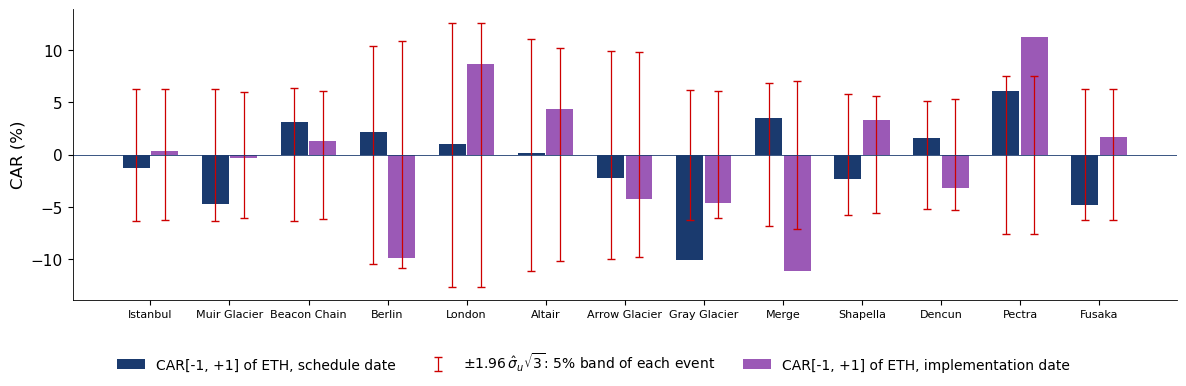

In [20]:
T['band'] = 1.96 * T['resid_sd'] * np.sqrt(3)
sch, imp_ = T[T.stage == 'schedule'].reset_index(drop=True), T[T.stage == 'implementation'].reset_index(drop=True)
print(f"Band from {T.band.min():.1f}% ({T.event[T.band.idxmin()]} {T.stage[T.band.idxmin()]}) to {T.band.max():.1f}% ({T.event[T.band.idxmax()]} {T.stage[T.band.idxmax()]})")
out_ = T[T.CAR_m1p1.abs() > T.band]
print(f'Outside the band: {len(out_)} of {len(T)} dates ({", ".join(out_.event + " " + out_.stage)}); expected by chance at 5%: {0.05 * len(T):.1f}')
fig, ax = plt.subplots(figsize=(12, 3.9))
xx = np.arange(len(EV))
for k, (tab, col, off, lb) in enumerate([(sch, BLUE, -0.18, 'schedule date'), (imp_, ETH, 0.18, 'implementation date')]):
    ax.bar(xx + off, tab['CAR_m1p1'], 0.34, color=col, label=f'CAR[-1, +1] of ETH, {lb}')
    ax.errorbar(xx + off, np.zeros(len(EV)), yerr=tab['band'], fmt='none', ecolor=RED, elinewidth=0.9, capsize=3,
                label=('$\\pm 1.96\\,\\hat\\sigma_u\\sqrt{3}$: 5% band of each event' if k == 0 else None))
ax.axhline(0, color=BLUE, lw=0.6)
ax.set_xticks(xx); ax.set_xticklabels([e[0] for e in EV], fontsize=8); ax.set_ylabel('CAR (%)')
legend_at_bottom(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l7_cars')

### Worked example: testing 13 CARs together

The cross-sectional test uses the spread of the 13 CARs across events, $s_{\mathrm{CAR}}$, not the residual sd of one market model: each upgrade may have its own true effect.

In [21]:
c13 = imp_['CAR_m1p1']
print('CARs[-1,+1], implementation (%):', ', '.join(f'{v:.2f}' for v in c13))
m_, s_ = c13.mean(), c13.std(ddof=1)
print(f'Step 1: mean = {c13.sum():.2f}/13 = {m_:.2f}%')
print(f'Step 2: s_CAR = {s_:.2f}%, standard error = {s_:.2f}/sqrt(13) = {s_ / np.sqrt(13):.2f}%')
t_ = m_ / (s_ / np.sqrt(13))
print(f'Step 3: t_CS = {t_:.2f}; critical value t(12, 0.975) = {stats.t.ppf(0.975, 12):.2f}; p = {2 * stats.t.sf(abs(t_), 12):.2f}')
npos = int((c13 > 0).sum())
print(f'Step 4: {npos} of 13 positive; sign test p = {stats.binomtest(npos, 13, 0.5).pvalue:.2f}')

CARs[-1,+1], implementation (%): 0.39, -0.31, 1.28, -9.91, 8.67, 4.35, -4.27, -4.59, -11.13, 3.32, -3.14, 11.25, 1.73
Step 1: mean = -2.36/13 = -0.18%
Step 2: s_CAR = 6.50%, standard error = 6.50/sqrt(13) = 1.80%
Step 3: t_CS = -0.10; critical value t(12, 0.975) = 2.18; p = 0.92
Step 4: 7 of 13 positive; sign test p = 1.00


### Abnormal returns around the event day

Each thin line is the cumulative abnormal return of ETH from day $-10$ to day $+10$ for one upgrade family; the thick line is the mean across the 13 families.

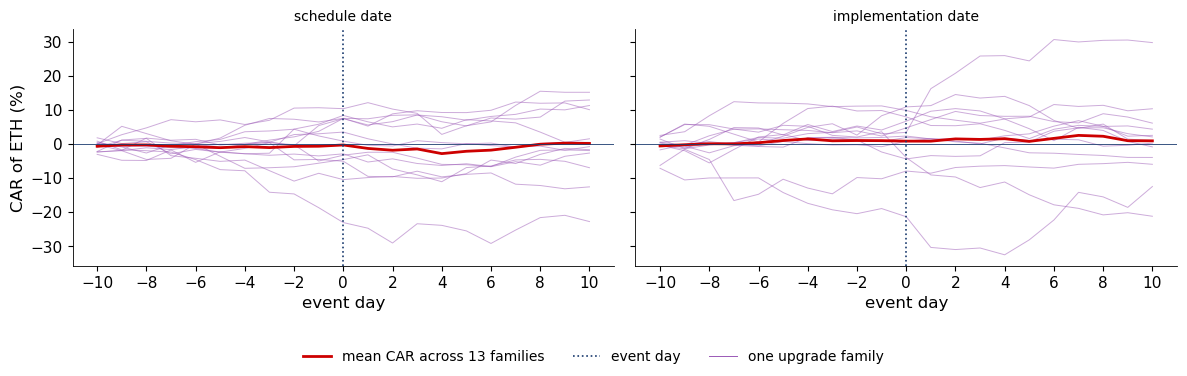

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
days = np.arange(-10, 11)
for k, stage in enumerate(['schedule', 'implementation']):
    Pp = np.array([paths[(n, stage)] for n, _, _ in EV])
    for p_ in Pp:
        ax[k].plot(days, p_, color=ETH, lw=0.7, alpha=0.5)
    ax[k].plot(days, Pp.mean(axis=0), color=RED, lw=2, label=('mean CAR across 13 families' if k == 0 else None))
    ax[k].axvline(0, color=BLUE, ls=':', lw=1.2, label=('event day' if k == 0 else None))
    ax[k].axhline(0, color=BLUE, lw=0.6)
    ax[k].set_title(f'{stage} date', fontsize=10); ax[k].set_xlabel('event day'); ax[k].set_xticks(range(-10, 11, 2))
ax[0].plot([], [], color=ETH, lw=0.7, label='one upgrade family')
ax[0].set_ylabel('CAR of ETH (%)')
legend_at_bottom(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l7_event')

### The paper: effects of Ethereum upgrades on market outcomes

Lin, Găman, Wang and Pele (2026), *When does the market react to protocol innovation? Evidence from the Ethereum upgrade lifecycle*, use the same 13 upgrade families but looks at outcomes beyond returns. It compares
ETH with donor coins by a cross-asset difference-in-differences and by synthetic control (SC), a weighted average of donor coins that tracks ETH
before the event:

$$ \hat\delta_{e,s} = \Delta y_{e,s,ETH} - \frac{1}{J_e}\sum_{j=1}^{J_e}\Delta y_{e,s,j}, \qquad \hat y^{SC}_{e,t} = \sum_j w_{e,j}\,y_{j,t},\; w_{e,j} \geq 0,\; \textstyle\sum_j w_{e,j} = 1 . $$

Inference uses exact sign-flip tests at family level, with Benjamini–Hochberg adjusted p-values (BH p).

| outcome (log points) | estimate | BH p |
|---|---:|---:|
| Google attention, schedule day | 0.184 | 0.034 |
| Google attention, implementation day | 0.350 | 0.004 |
| active addresses, implementation (synthetic control) | −0.145 | 0.020 |
| median hourly log realised volatility (RV), implementation hours | 0.316 | 0.007 |
| jump share, bipower variation (24 h) | ≈ 0 | 0.99 |
| paired CAR, implementation minus schedule | −0.0098 | raw p 0.375 |

The event goes with more attention and volatility and fewer active addresses. A non-significant CAR does not prove that upgrades are already
priced in, and fewer active addresses do not show that users pause: both are hypotheses consistent with these estimates.

## 4. Sentiment from social media

### BitMood: building a sentiment index

The BitMood study (Conda, Găman, Bâg, Mazurencu-Marinescu-Pele, Pele and Härdle, 2026, *Digital Finance*) uses 120,000 English Facebook posts on Bitcoin (a 5% monthly sample of about 2.3 million posts collected with CrowdTangle),
3 January 2015 – 15 October 2023. The post texts are not part of the course data, so this section shows how the index is built rather than re-estimating it.

FinBERT, a language model trained on financial text, gives each post $i$ the probabilities $S^+_i, S^0_i, S^-_i$ of positive, neutral and negative
tone; the compound score is $\mathrm{CS}_i = S^+_i - S^-_i$. With $T_i$ the total interactions of post $i$, the engagement-weighted daily
compound score (WC) is

$$ P^{\pm,0}_d = \frac{\sum_{i \in d} S^{\pm,0}_i T_i}{\sum_{i \in d} T_i}, \qquad \mathrm{WC}_d = \frac{P^+_d - P^-_d}{P^+_d + P^-_d + P^0_d} \in [-1, 1] . $$

The reaction-intensity score (SI) of a post is $\mathrm{SI}_i = \sum_k(\log N_{i,k} + 1)\,w_k$, where $N_{i,k}$ counts reactions of type $k$ with weights
like 0.1, comment 0.05, share 0.2, love/wow/haha 0.5, sad/angry $-0.5$. Since $\log 0$ is undefined and the article does not say how posts
with no reactions of a type are treated, an implementation needs a rule such as $\log(1 + N_{i,k})$. Topics come from latent Dirichlet allocation (LDA): investment 42.8%,
trading and blockchain 24.6%, gaming 14.3%, social-media links 13%, business 5.3% of tokens.

The cell below applies the WC formula to three illustrative posts of one day, to show how engagement weighting works.

In [23]:
# three illustrative posts of one day: FinBERT probabilities and total interactions
posts = pd.DataFrame({'S_pos': [0.80, 0.10, 0.30], 'S_neu': [0.15, 0.20, 0.60], 'S_neg': [0.05, 0.70, 0.10],
                      'interactions': [50, 900, 50]}, index=['post A', 'post B', 'post C'])
posts['compound CS'] = posts['S_pos'] - posts['S_neg']
w = posts['interactions'] / posts['interactions'].sum()
Pp, P0, Pm = (w * posts['S_pos']).sum(), (w * posts['S_neu']).sum(), (w * posts['S_neg']).sum()
WC = (Pp - Pm) / (Pp + Pm + P0)
print(posts.to_string())
print(f'\nUnweighted mean compound score: {posts["compound CS"].mean():+.3f}')
print(f'Engagement-weighted daily score WC: {WC:+.3f}  (the negative post B has 90% of the interactions)')

        S_pos  S_neu  S_neg  interactions  compound CS
post A    0.8   0.15   0.05            50         0.75
post B    0.1   0.20   0.70           900        -0.60
post C    0.3   0.60   0.10            50         0.20

Unweighted mean compound score: +0.117
Engagement-weighted daily score WC: -0.492  (the negative post B has 90% of the interactions)


### BitMood: what sentiment can and cannot do

The study tests a contrarian rule (after Preis et al.): compare today's sentiment $f(t)$ with its mean over the previous $\delta t$ days,

$$ \Delta f(t, \delta t) = f(t) - \frac{1}{\delta t}\sum_{k=1}^{\delta t} f(t-k), $$

and buy when sentiment fell ($\Delta f < 0$), sell when it rose. The best configuration in the test period 1 January – 15 October 2023
($\delta t = 3$ days, compound sentiment, cost $10^{-5}$) gives a cumulative return of 1.321 and a Sharpe ratio (mean strategy return divided by its
standard deviation) of 0.210. The article does not say whether the return is simple, log or a wealth multiple, or whether the Sharpe ratio is daily
or annualised; a cost of $10^{-5}$ as a fraction of the amount traded is 0.1 basis point per trade, far below typical exchange fees.

Volume forecasts (daily Bitcoin trading volume, January 2022 – October 2023), root mean squared error (RMSE) of scaled volume, for linear regression, random forest (RF), long short-term memory (LSTM),
convolutional (CNN) and gated recurrent unit (GRU) networks:

| | Lin. reg. | RF | stacked LSTM | CNN | LSTM-CNN | GRU | Bi-LSTM |
|---|---:|---:|---:|---:|---:|---:|---:|
| validation | **0.1423** | 0.1767 | 0.2323 | 0.2179 | 0.2501 | 0.1840 | 0.1701 |
| test | **0.1935** | 0.2355 | 0.2453 | 0.2578 | 0.2766 | 0.1959 | 0.1930 |

* Select on validation, report on test: the linear regression has the lowest validation RMSE (0.1423) and a test RMSE of 0.1935, 0.0005 above the best test value (Bi-LSTM).
* The best of many window–feature–cost combinations (7 windows × 6 costs × several sentiment series) was chosen on the same 2023 period on which
  it is scored. An honest test selects the configuration on earlier data.
* Lagged volume and negative sentiment dominate the Shapley additive explanations (SHAP) of the linear model. Every model in the table uses
  sentiment, so the table does not show that sentiment improves on lagged volume alone: that needs the same model without the sentiment features,
  scored on the same test days, with the RMSE difference and its uncertainty. SHAP does not replace that test. The study gives no evidence on returns.

**Before trusting a back-test (the minimum standard).** Use three periods in time order: training (estimate), validation (choose the model,
window, threshold or cost setting) and test (score the chosen configuration once). Compare with a benchmark without the new information on the
same test days, report the difference with its uncertainty, and report how many configurations were tried. Lecture 8 applies this standard to
machine-learning forecasts of Bitcoin.

The function below implements $\Delta f$ and the contrarian position, so it can be applied to any daily sentiment series.

In [24]:
def contrarian_position(f, dt=3):
    """Delta f(t, dt) = f(t) - mean of the previous dt values; position +1 (buy) if sentiment fell, -1 (sell) if it rose."""
    delta = f - f.shift(1).rolling(dt).mean()
    return delta, -np.sign(delta)


f = pd.Series([0.10, 0.12, 0.08, 0.15, 0.02, 0.05], index=pd.date_range('2023-03-01', periods=6), name='sentiment')
delta, pos = contrarian_position(f, dt=3)
print(pd.DataFrame({'sentiment f(t)': f, 'Delta f(t, 3)': delta.round(3), 'position (+1 buy, -1 sell)': pos}).to_string())

            sentiment f(t)  Delta f(t, 3)  position (+1 buy, -1 sell)
2023-03-01            0.10            NaN                         NaN
2023-03-02            0.12            NaN                         NaN
2023-03-03            0.08            NaN                         NaN
2023-03-04            0.15          0.050                        -1.0
2023-03-05            0.02         -0.097                         1.0
2023-03-06            0.05         -0.033                         1.0


### A lagged-volume benchmark for BitMood

Any sentiment model of volume must beat a forecast from past volume alone. The cell measures how persistent the log of daily Bitcoin trading
volume (EODHD) was over the BitMood volume sample, 1 January 2022 – 15 October 2023: autocorrelations, the weekly pattern, an autoregression of order 1, AR(1),
and the root mean squared error (RMSE, in logs) of three simple forecasts.

653 days; autocorrelation of log volume: lag 1 0.78, lag 7 0.74, lag 30 0.39
Log volume minus its mean: Saturday -0.33, Sunday -0.28
AR(1): R^2 = 0.61
RMSE in logs: sample mean 0.50, same as yesterday 0.33, AR(1) 0.31


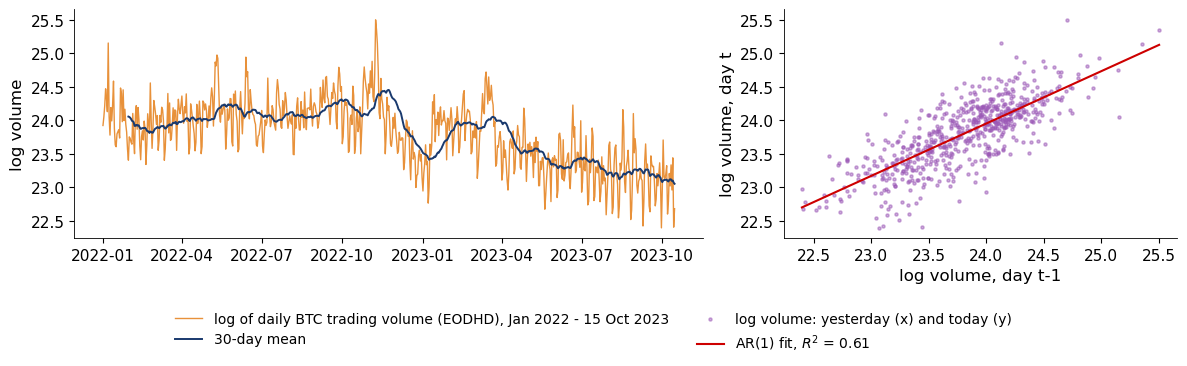

In [25]:
vol_btc = pd.read_csv(data_file('market', 'BTC-USD.CC.csv'), parse_dates=['date']).set_index('date')['volume'].loc[:END]
lvol = np.log(vol_btc.replace(0, np.nan)).dropna()
v = lvol.loc['2022-01-01':'2023-10-15']
x1, y1 = v.shift(1).dropna(), v.iloc[1:]
b1, a1 = np.polyfit(x1, y1, 1)
res_ = y1 - (a1 + b1 * x1)
print(f'{len(v)} days; autocorrelation of log volume: lag 1 {v.autocorr(1):.2f}, lag 7 {v.autocorr(7):.2f}, lag 30 {v.autocorr(30):.2f}')
dev = v.groupby(v.index.dayofweek).mean() - v.mean()
print(f'Log volume minus its mean: Saturday {dev[5]:+.2f}, Sunday {dev[6]:+.2f}')
print(f'AR(1): R^2 = {1 - res_.var() / y1.var():.2f}')
print(f'RMSE in logs: sample mean {np.sqrt(np.mean((y1 - y1.mean()) ** 2)):.2f}, same as yesterday {np.sqrt(np.mean((y1 - x1) ** 2)):.2f}, AR(1) {np.sqrt(np.mean(res_ ** 2)):.2f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.7), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(v.index, v, color=BTC, lw=1.0, label='log of daily BTC trading volume (EODHD), Jan 2022 - 15 Oct 2023')
ax[0].plot(v.index, v.rolling(30).mean(), color=BLUE, lw=1.4, label='30-day mean')
ax[0].set_ylabel('log volume')
ax[1].scatter(x1, y1, s=5, color=ETH, alpha=0.5, label='log volume: yesterday (x) and today (y)')
xx = np.linspace(x1.min(), x1.max(), 20)
ax[1].plot(xx, a1 + b1 * xx, color=RED, lw=1.5, label=f'AR(1) fit, $R^2$ = {1 - res_.var() / y1.var():.2f}')
ax[1].set_xlabel('log volume, day t-1'); ax[1].set_ylabel('log volume, day t')
legend_at_bottom(fig, ncol=2, bottom=0.17)
save_fig(fig, 'ba_l7_volume')

## Appendix (not examined)

### Herding: the CSAD test

The cross-sectional absolute deviation (CSAD) measures how far coin returns spread around the market return $R_{m,t}$ (here the equal-weighted
mean of the 19 coins):

$$ \mathrm{CSAD}_t = \frac1N\sum_{i=1}^N |R_{i,t} - R_{m,t}| . $$

Under rational pricing (the capital asset pricing model, CAPM), dispersion rises linearly with $|R_{m,t}|$. Under herding, coins move together
in large market moves and dispersion rises *less*. Chang, Cheng and Khorana (2000) test this with

$$ \mathrm{CSAD}_t = \alpha + \gamma_1 |R_{m,t}| + \gamma_2 R_{m,t}^2 + \varepsilon_t, \qquad H_0: \gamma_2 = 0, \quad \text{herding: } \gamma_2 < 0 . $$

Standard errors are heteroskedasticity and autocorrelation consistent (HAC) with 10 lags. The regression is run on all days, on up days
($R_m > 0$) and on down days, and then on rolling 365-day windows moved forward 15 days at a time.

In [26]:
Rm = R.mean(axis=1)
csad = R.sub(Rm, axis=0).abs().mean(axis=1)
X = sm.add_constant(pd.DataFrame({'absRm': Rm.abs(), 'Rm2': Rm ** 2}))
hac = dict(cov_type='HAC', cov_kwds={'maxlags': 10})
fits = {'all days': sm.OLS(csad, X).fit(**hac),
        'up days (R_m > 0)': sm.OLS(csad[Rm > 0], X[Rm > 0]).fit(**hac),
        'down days (R_m <= 0)': sm.OLS(csad[Rm <= 0], X[Rm <= 0]).fit(**hac)}
print(pd.DataFrame({k: {'alpha': m.params['const'], 'gamma_1': m.params['absRm'], 't(gamma_1)': m.tvalues['absRm'],
                        'gamma_2': m.params['Rm2'], 't(gamma_2)': m.tvalues['Rm2'], 'R2': m.rsquared, 'days': int(m.nobs)}
                    for k, m in fits.items()}).T.round(4).to_string())
h = fits['all days']
print(f"\nVertex of the fitted curve: |R_m| = gamma_1 / (2 |gamma_2|) = {h.params['absRm'] / (2 * abs(h.params['Rm2'])):.0f}%")
print(f'Days with |R_m| > 15%: {(Rm.abs() > 15).sum()}')

rg = {}
for k in range(365, len(R) + 1, 15):
    sl = slice(k - 365, k)
    m = sm.OLS(csad.iloc[sl], X.iloc[sl]).fit(**hac)
    rg[R.index[k - 1]] = (m.params['Rm2'], m.tvalues['Rm2'])
rg = pd.DataFrame(rg, index=['g2', 't']).T
print(f"Rolling 365-day windows: gamma_2 significantly negative (t < -1.96) in {100 * (rg['t'] < -1.96).mean():.1f}% of windows, "
      f"significantly positive (t > 1.96) in {100 * (rg['t'] > 1.96).mean():.1f}%")

                       alpha  gamma_1  t(gamma_1)  gamma_2  t(gamma_2)      R2    days
all days              1.2194   0.2542     10.7584  -0.0028     -2.8838  0.2476  2121.0
up days (R_m > 0)     1.1652   0.3179      4.4155   0.0003      0.0340  0.3013  1122.0
down days (R_m <= 0)  1.2962   0.1511      6.9721  -0.0001     -0.1205  0.2576   999.0

Vertex of the fitted curve: |R_m| = gamma_1 / (2 |gamma_2|) = 45%
Days with |R_m| > 15%: 16
Rolling 365-day windows: gamma_2 significantly negative (t < -1.96) in 1.7% of windows, significantly positive (t > 1.96) in 39.0%


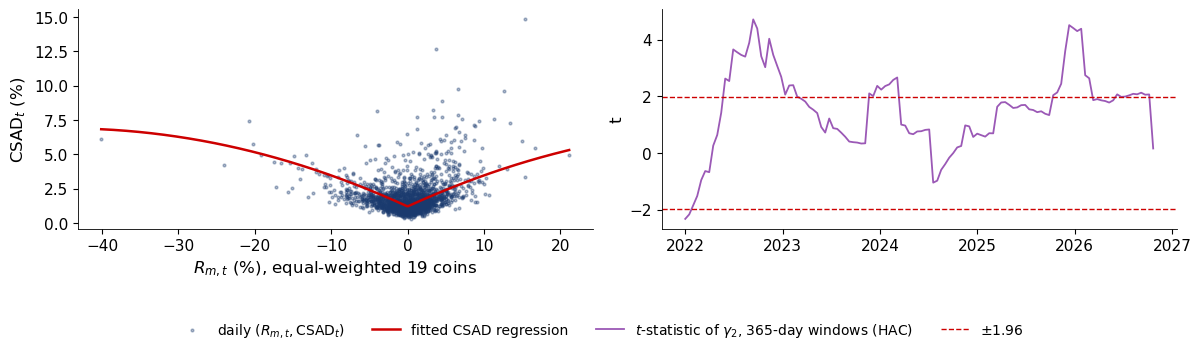

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].scatter(Rm, csad, s=4, color=BLUE, alpha=0.35, label=r'daily $(R_{m,t}, \mathrm{CSAD}_t)$')
xx = np.linspace(Rm.min(), Rm.max(), 300)
ax[0].plot(xx, h.params['const'] + h.params['absRm'] * np.abs(xx) + h.params['Rm2'] * xx ** 2, color=RED, lw=1.8, label='fitted CSAD regression')
ax[0].set_xlabel(r'$R_{m,t}$ (%), equal-weighted 19 coins'); ax[0].set_ylabel(r'CSAD$_t$ (%)')
ax[1].plot(rg.index, rg['t'], color=ETH, lw=1.3, label=r'$t$-statistic of $\gamma_2$, 365-day windows (HAC)')
ax[1].axhline(-1.96, color=RED, ls='--', lw=1, label=r'$\pm 1.96$'); ax[1].axhline(1.96, color=RED, ls='--', lw=1)
ax[1].set_ylabel('t')
legend_at_bottom(fig, ncol=4, bottom=0.15)
save_fig(fig, 'ba_l7_csad')

### Hedonic price indices: an example on simulated sales

Each non-fungible token (NFT) or digital artwork is unique and trades rarely, so the works sold this quarter differ from those sold last quarter.
A median sale price mixes price changes with **composition** changes. The time-dummy hedonic regression on all sales $n$ in quarters $t = 0, \dots, T$,

$$ \ln P_{n} = \sum_{t=1}^{T}\delta_t D_{n,t} + \mathbf x_n'\boldsymbol\beta + \varepsilon_n, \qquad I_t = 100\,e^{\hat\delta_t}, $$

controls for the characteristics $\mathbf x_n$ (rarity, known artist, size), so $\hat\delta_t$ is a quality-adjusted log price level.

The simulation below has 12 quarters with 300 sales each and a known true index (a boom and a bust). In the boom (quarters 2–5) more
low-rarity works by unknown artists are sold. Because the true index is known, both estimators can be scored by their root mean squared error (RMSE) in logs.

Simulated sales: 3600
Estimated effect of rarity 2.52 (true 2.5), of a known artist 1.20 (true 1.2); R2 = 0.624
                 0     1     2     3     4     5     6     7     8     9     10    11
true log index  0.0  0.25  0.60  1.10  1.50  1.20  0.50 -0.10 -0.30 -0.20  0.00  0.10
hedonic         0.0  0.30  0.69  1.21  1.55  1.28  0.63 -0.01 -0.18 -0.13  0.09  0.15
median price    0.0  0.48  0.31  0.76  1.15  0.80  0.69  0.09 -0.11  0.04  0.05  0.34
RMSE in logs: hedonic 0.085, median 0.252
Peak (quarter 4), index with quarter 0 = 100: true 448, hedonic 469, median 315


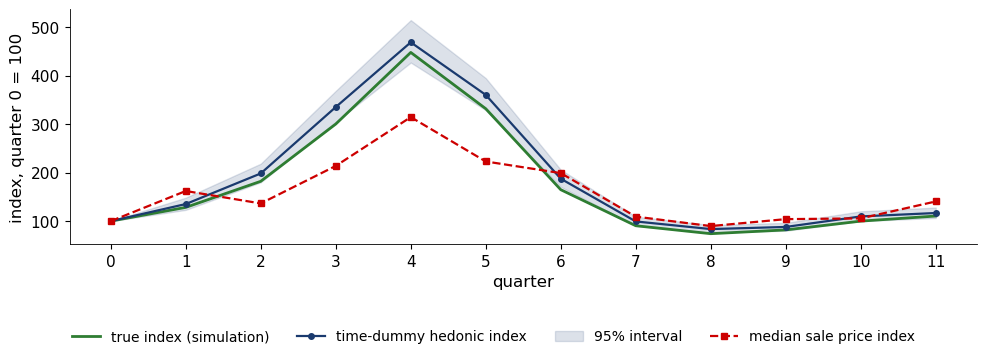

In [28]:
rng = np.random.default_rng(42)
TQ = 12
true = np.array([0, 0.25, 0.6, 1.1, 1.5, 1.2, 0.5, -0.1, -0.3, -0.2, 0.0, 0.1])     # true log index
rows = []
for t in range(TQ):
    n = 300
    boom = 1 if 2 <= t <= 5 else 0
    rarity = rng.beta(2, 5 + 4 * boom, n)
    known = rng.random(n) < (0.35 - 0.2 * boom)
    size = rng.normal(0, 1, n)
    lp = 6 + true[t] + 2.5 * rarity + 1.2 * known + 0.1 * size + rng.normal(0, 0.6, n)
    rows.append(pd.DataFrame(dict(q=t, lp=lp, rarity=rarity, known=known.astype(int), size=size)))
DS = pd.concat(rows)
mh = smf.ols('lp ~ C(q) + rarity + known + size', data=DS).fit(cov_type='HC1')
hed = np.r_[0, [mh.params[f'C(q)[T.{t}]'] for t in range(1, TQ)]]
se = np.r_[0, [mh.bse[f'C(q)[T.{t}]'] for t in range(1, TQ)]]
med = np.log(DS.groupby('q')['lp'].apply(lambda x: np.exp(x).median()).values)
med = med - med[0]
print(f'Simulated sales: {len(DS)}')
print(f"Estimated effect of rarity {mh.params['rarity']:.2f} (true 2.5), of a known artist {mh.params['known']:.2f} (true 1.2); R2 = {mh.rsquared:.3f}")
print(pd.DataFrame({'true log index': true, 'hedonic': hed, 'median price': med}).round(2).T.to_string())
print(f'RMSE in logs: hedonic {np.sqrt(np.mean((hed - true) ** 2)):.3f}, median {np.sqrt(np.mean((med - true) ** 2)):.3f}')
print(f'Peak (quarter 4), index with quarter 0 = 100: true {100 * np.exp(true[4]):.0f}, hedonic {100 * np.exp(hed[4]):.0f}, median {100 * np.exp(med[4]):.0f}')

fig, ax = plt.subplots(figsize=(10, 3.6))
q = np.arange(TQ)
ax.plot(q, 100 * np.exp(true), color=GREEN, lw=2, label='true index (simulation)')
ax.plot(q, 100 * np.exp(hed), color=BLUE, lw=1.6, marker='o', ms=4, label='time-dummy hedonic index')
ax.fill_between(q, 100 * np.exp(hed - 1.96 * se), 100 * np.exp(hed + 1.96 * se), color=BLUE, alpha=0.15, label='95% interval')
ax.plot(q, 100 * np.exp(med), color=RED, lw=1.6, ls='--', marker='s', ms=4, label='median sale price index')
ax.set_xlabel('quarter'); ax.set_ylabel('index, quarter 0 = 100'); ax.set_xticks(q)
legend_at_bottom(fig, ncol=4, bottom=0.13)
save_fig(fig, 'ba_l7_hedonic')

## References

* Mantegna, R. N. (1999). Hierarchical structure in financial markets. *European Physical Journal B*, 11, 193–197. [doi:10.1007/s100510050929](https://doi.org/10.1007/s100510050929)
* Diebold, F. X., Yilmaz, K. (2012). Better to give than to receive: predictive directional measurement of volatility spillovers. *International Journal of Forecasting*, 28(1), 57–66. [doi:10.1016/j.ijforecast.2011.02.006](https://doi.org/10.1016/j.ijforecast.2011.02.006)
* Pele, D. T., Wesselhöfft, N., Härdle, W. K., Kolossiatis, M., Yatracos, Y. G. (2023). Are cryptos becoming alternative assets? *European Journal of Finance*. [doi:10.1080/1351847X.2021.1960403](https://doi.org/10.1080/1351847X.2021.1960403)
* MacKinlay, A. C. (1997). Event studies in economics and finance. *Journal of Economic Literature*, 35(1), 13–39. [JSTOR](https://www.jstor.org/stable/2729691)
* Lin, Găman, Wang, Pele (2026). When does the market react to protocol innovation? Evidence from the Ethereum upgrade lifecycle. Working paper.
* Conda, A. I., Găman, Ș., Bâg, R. C., Mazurencu-Marinescu-Pele, M., Pele, D. T., Härdle, W. K. (2026). BitMood: AI analysis of Bitcoin trends via Facebook emotions. *Digital Finance*, 8, article 42. [doi:10.1007/s42521-026-00205-3](https://doi.org/10.1007/s42521-026-00205-3)
* Christie, W. G., Huang, R. D. (1995). Following the pied piper: do individual returns herd around the market? *Financial Analysts Journal*, 51(4), 31–37. [doi:10.2469/faj.v51.n4.1918](https://doi.org/10.2469/faj.v51.n4.1918)
* Chang, E. C., Cheng, J. W., Khorana, A. (2000). An examination of herd behavior in equity markets: an international perspective. *Journal of Banking & Finance*, 24(10), 1651–1679. [doi:10.1016/S0378-4266(99)00096-5](https://doi.org/10.1016/S0378-4266(99)00096-5)